# 1. Data collection and exploratory analysis

**Question.** At the moment an e-commerce order is placed, can we tell how likely it is to arrive *after the date promised to the customer*?

**Why it matters.** A missed delivery promise costs reviews, repeat purchases and support effort. If risky orders can be spotted at checkout, the company can act: pick a faster carrier, set a more honest promise, or message the customer early.

**This notebook** covers where the data comes from, how the label is defined, and what the data says about lateness before any model is built. Run it top to bottom. Every section has: **what and why**, then **code**, then **how to read the output**.

| Section | Topic |
|---|---|
| 1 | The data: Olist plus two public APIs collected for this project |
| 2 | Defining the label (and a trap in the timestamps) |
| 3 | When: lateness comes in bursts |
| 4 | Promises: padded, and still missed |
| 5 | Where: states and distance |
| 6 | Who: sellers, and why "concentrated" is not "persistent" |
| 7 | Why it matters: reviews |
| 8 | Weather and holidays: a raw signal that needs a second look |
| 9 | What this means for modelling |

## Setup

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)
pd.set_option("display.width", 130, "display.max_columns", 30, "display.float_format", lambda v: f"{v:,.4f}")
FIG = ROOT / "reports" / "figures"
def show(name, width=760): display(Image(filename=str(FIG / name), width=width))

## 1. The data

**What and why.** The main source is the [Olist Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (about 100,000 orders from 2016 to 2018, license CC BY-NC-SA 4.0): orders, items, payments, customers, sellers, products, reviews and geolocation.
On its own it cannot tell us about holidays or weather, so two **external sources** were collected with `python -m delivery.collect`, both free and without an API key:

- **Public holidays** for Brazil from the Nager.Date API (only national holidays and Carnival are used; state-only holidays are ignored).
- **Daily rainfall and temperature** for each of the 27 states from the Open-Meteo historical weather API, at the centroid of the state's Olist zip codes.

`load_orders()` joins the raw tables into **one row per order**, keeping only facts that are known *when the order is placed*, plus outcome columns that are used for labels and for *past* statistics, never as inputs for the same order.

In [2]:
from delivery.data import load_orders
df = load_orders()
print(f"{len(df):,} orders with at least one item | {int(df.delivered.sum()):,} have a recorded delivery")
display(df[["purchase_ts", "promised_date", "delivered_ts", "seller_state", "customer_state", "distance_km", "total_price", "total_freight", "late"]].head())
hol = pd.read_csv("data/external/holidays_br.csv", parse_dates=["date"]); wx = pd.read_csv("data/external/weather_by_state.csv", parse_dates=["date"])
print(f"collected: {len(hol)} holiday rows and {len(wx):,} state-days of weather ({wx.state.nunique()} states, {wx.date.min().date()} to {wx.date.max().date()})")

98,666 orders with at least one item | 96,470 have a recorded delivery


,purchase_ts,promised_date,delivered_ts,seller_state,customer_state,distance_km,total_price,total_freight,late
0,2016-09-04 21:15:19,2016-10-20,NaT,MG,RR,"3,198.8431",72.8900,63.3400,NaN
1,2016-09-05 00:15:34,2016-10-28,NaT,PR,RS,437.1271,59.5000,15.5600,NaN
2,2016-09-15 12:16:38,2016-10-04,2016-11-09 07:47:38,PR,SP,565.9598,134.9700,8.4900,1.0000
3,2016-10-02 22:07:52,2016-10-25,NaT,SP,SP,10.2391,100.0000,9.3400,NaN
4,2016-10-03 09:44:50,2016-10-27,2016-10-26 14:02:13,PR,SP,708.7542,29.9000,15.5600,0.0000


collected: 56 holiday rows and 22,194 state-days of weather (27 states, 2016-08-01 to 2018-10-31)


**How to read this.** `late` is empty (NaN) for orders that were never delivered, so only delivered orders can be used for training and evaluation. That is a limit of the data: orders that were lost or are still in transit are invisible.
`distance_km` is the straight-line distance between the seller's and the customer's zip-code areas, built from Olist's own geolocation table.

## 2. Defining the label

**What and why.** An order is *late* if it is delivered after the promised date. There is a trap: the promised date has **no time of day** (midnight), while the delivery has a full timestamp. A naive comparison `delivered_ts > promised_date` marks an order delivered at 10:00 *on* the promised day as late, which is wrong from the customer's point of view.
The label therefore compares **calendar days**.

In [3]:
d = df[df.delivered]
naive = (d.delivered_ts > d.promised_date).mean()
by_day = d.late.mean()
print(f"naive timestamp comparison: {naive:.2%} late   |   calendar-day comparison (used): {by_day:.2%} late")
print(f"orders delivered on the promised day, wrongly 'late' under the naive rule: {int(((d.delivered_ts > d.promised_date) & (d.late == 0)).sum()):,}")

naive timestamp comparison: 8.11% late   |   calendar-day comparison (used): 6.77% late
orders delivered on the promised day, wrongly 'late' under the naive rule: 1,292


**How to read this.** About 1.3 percentage points of "lateness" would have been a labelling artifact. The project uses the calendar-day label: **6.8% of delivered orders are late**. A `test_label_is_calendar_day_comparison` unit test locks this in.

## 3. When: lateness comes in bursts

**What and why.** Is lateness a steady background rate, or does it come in waves? This decides how any model must be validated: with a steady rate a random split is fine; with waves you must test on a *later* period.

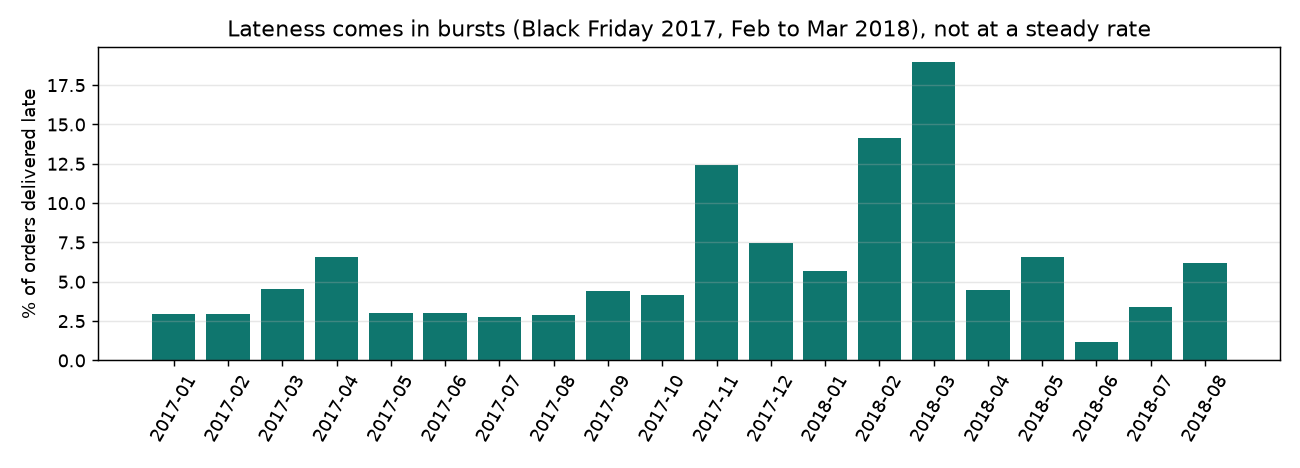

In [4]:
from delivery.eda import run_eda
X = pd.read_parquet("data/processed/features.parquet") if Path("data/processed/features.parquet").exists() else None
from delivery.pipeline import prepare
df, Xf, masks, enc, hol = prepare()
eda = run_eda(df, Xf)
show("01_late_rate_by_month.png", 900)

**How to read this.** Lateness runs at 3% for most of 2017, jumps to **12% in November 2017 (Black Friday)**, **14% in February 2018 and 19% in March 2018**, then drops to 1 to 7% in spring and summer. The rate is driven by events, not by a steady process.
Consequence: the model must be evaluated on later periods than it was trained on, with its calibration checked across regimes. That is what the rest of the project does.

## 4. Promises: padded, and still missed

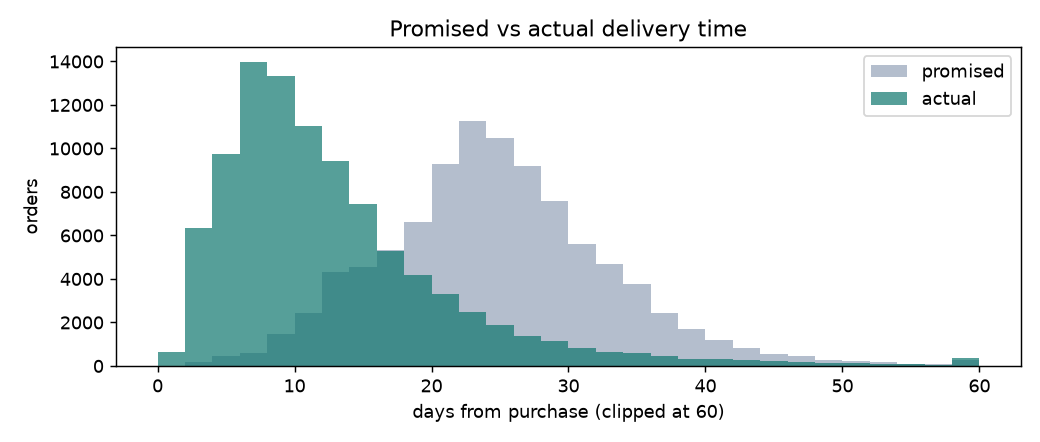

median promised: 24 days | median actual: 10 days
late rate by promised days: {'(0, 10]': '10.5%', '(10, 15]': '4.1%', '(15, 20]': '7.1%', '(20, 25]': '8.1%', '(25, 30]': '7.1%', '(30, 40]': '5.6%', '(40, 200]': '2.4%'}


In [5]:
show("02_promised_vs_actual.png", 600)
print(f"median promised: {eda['median_promised_days']:.0f} days | median actual: {eda['median_actual_days']:.0f} days")
print("late rate by promised days:", {k: f"{v:.1%}" for k, v in eda["late_rate_by_promised_days"].items()})

**How to read this.** The median promise is **24 days**; the median delivery takes **10**. Promises include a large safety margin, yet 6.8% of orders still miss them. The promise length itself carries information: very short promises (10 days or less) are late **10.5%** of the time, because there is little margin, while promises of 40 or more days are late only **2.4%** of the time. This is why the promise-and-calendar features turn out to be the most important group later.

## 5. Where: states and distance

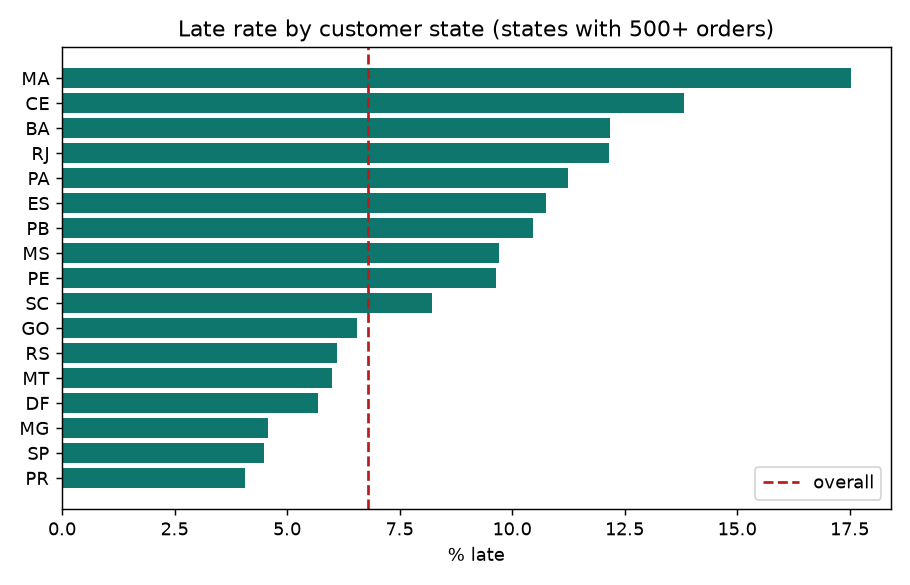

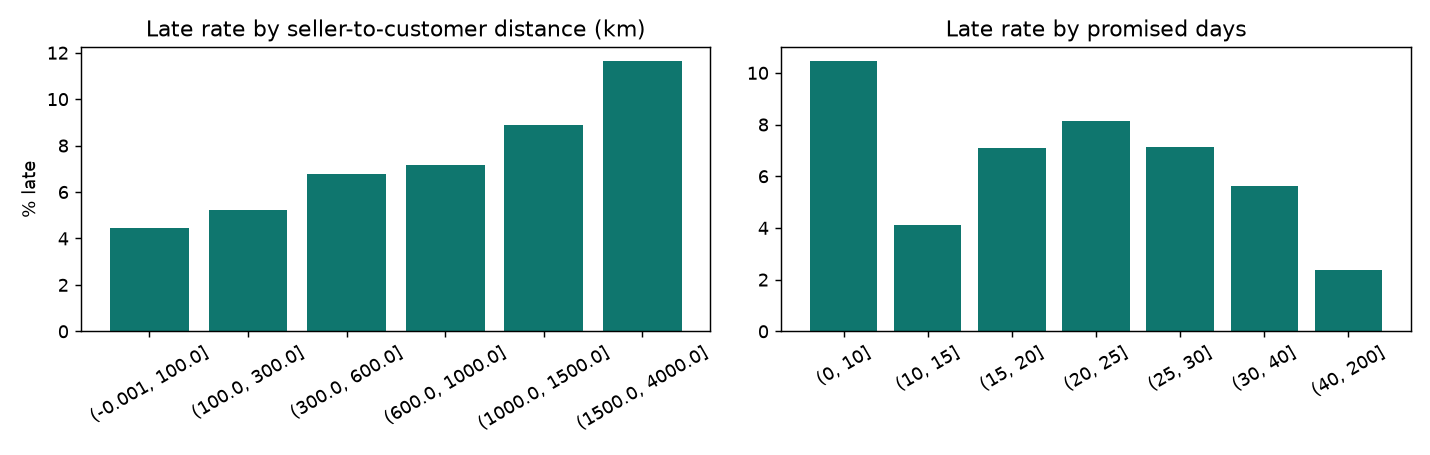

In [6]:
show("03_late_rate_by_state.png", 520); show("04_distance_and_promise.png", 900)

**How to read this.** Late rates vary by customer state, and rise steadily with distance: **4.5% under 100 km to 11.7% beyond 1,500 km**. Geography is the second most important feature group in the model.

## 6. Who: sellers, and why "concentrated" is not "persistent"

**What and why.** An obvious idea is to find the bad sellers. The data seems to agree: a small share of sellers accounts for most late orders. But a model can only use the past to predict the future, so the question that matters is whether the *same* sellers stay late.

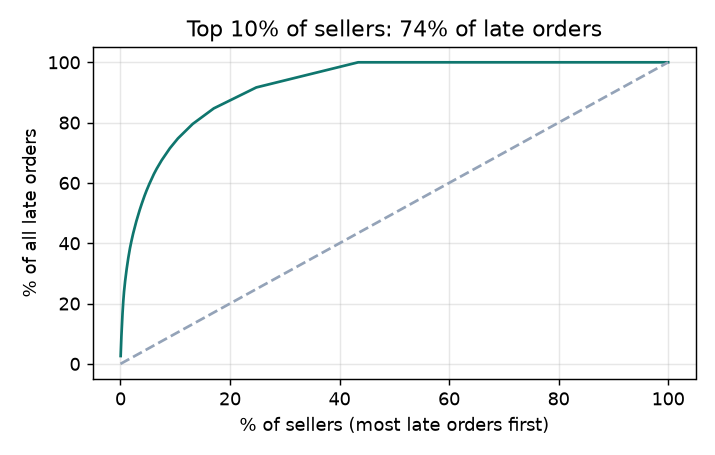

top 10% of sellers account for 74% of all late orders (within the whole period)

sellers with enough orders in both halves of the training year: 106
rank correlation of a seller's late rate across the two periods: 0.21  (1 = perfectly persistent, 0 = no relation)


In [7]:
show("06_seller_concentration.png", 460)
print(f"top 10% of sellers account for {eda['late_orders_share_top10pct_sellers']:.0%} of all late orders (within the whole period)")

# persistence: does a seller's late rate in one period predict their late rate in the next?
from scipy.stats import spearmanr
d = df[df.delivered]
def rate(mask, min_orders):
    g = d[mask].groupby("seller_id")["late"].agg(["mean", "size"]); return g[g["size"] >= min_orders]["mean"]
a = rate((d.purchase_ts >= "2017-01-01") & (d.purchase_ts < "2017-08-01"), 30)
b = rate((d.purchase_ts >= "2017-08-01") & (d.purchase_ts < "2018-01-15"), 30)
j = a.index.intersection(b.index)
print(f"\nsellers with enough orders in both halves of the training year: {len(j)}")
print(f"rank correlation of a seller's late rate across the two periods: {spearmanr(a[j], b[j])[0]:.2f}  (1 = perfectly persistent, 0 = no relation)")

**How to read this.** The top 10% of sellers do account for about **74%** of late orders. But the rank correlation of a seller's late rate between two periods is only about **0.2** (and about 0.09 from training to the test period). Lateness is mostly **event-driven**: a bad week hits many sellers at once, and the sellers who suffered one week are not reliably the ones who suffer the next.
This is a general lesson: *a distribution that is concentrated within a period can still be unpredictable across periods*. It is also why "seller's historical late rate" on its own scores no better than chance on the test set (ROC-AUC 0.51).

## 7. Why it matters: reviews

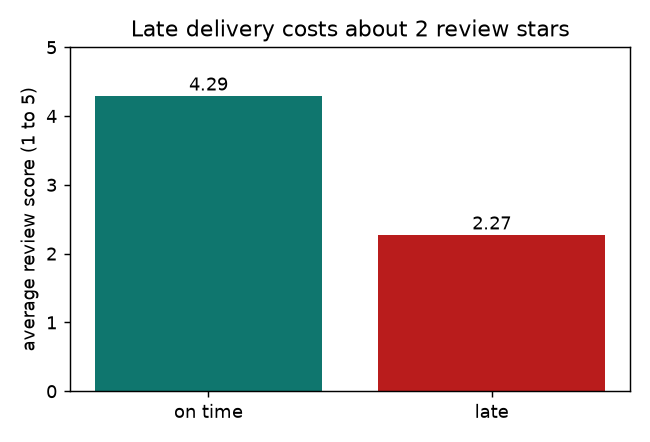

average review: 4.29 on time vs 2.27 late
1-star reviews: 7% of on-time orders vs 54% of late orders


In [8]:
show("05_review_score_by_lateness.png", 420)
print(f"average review: {eda['review_score_on_time']:.2f} on time vs {eda['review_score_late']:.2f} late")
print(f"1-star reviews: {eda['one_star_share_on_time']:.0%} of on-time orders vs {eda['one_star_share_late']:.0%} of late orders")

**How to read this.** A late delivery costs about **two review stars**, and more than half of late orders get a 1-star review. That is the business case for predicting lateness; it also gives a rough scale for how expensive a late order is compared with an intervention (used in the cost analysis in notebook 2).

## 8. Weather and holidays: a raw signal that needs a second look

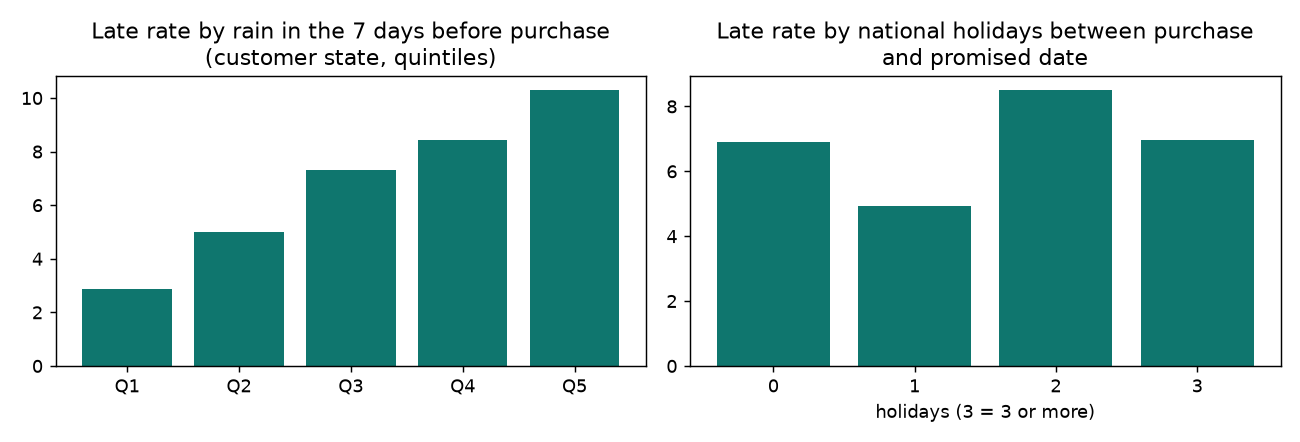

late rate by rain quintile (7 days before purchase, customer state): ['2.9%', '5.0%', '7.3%', '8.4%', '10.3%']


In [9]:
show("07_weather_and_holidays.png", 820)
print("late rate by rain quintile (7 days before purchase, customer state):", [f"{v:.1%}" for v in eda["late_rate_by_rain_quintile"]])

**How to read this.** The raw association with rain looks **strong**: late rate rises from 2.9% (driest fifth) to 10.3% (wettest fifth). Holidays show no clear pattern.
Before believing the rain effect, ask what else changes with rain. Rainy periods coincide with the Black Friday and February-March spikes, and rainy regions are far from the main shipping hubs, so rain is partly standing in for *season and geography*. The honest test is whether weather still helps **once the other features are in the model**: it adds only about 0.002 ROC-AUC in cross-validation (notebook 2). The data collection was worth doing, because it produced a definite answer: *rainfall adds almost nothing beyond the promise, geography and recent system lateness*.

## 9. What this means for modelling

| Finding | Consequence |
|---|---|
| Lateness is bursty and event-driven | Validate on later periods, with maturity gaps; expect calibration to depend on the regime |
| Late deliveries resolve slowly (60% of late orders are still undelivered after 4 weeks) | Leave a 45-day gap before each evaluation period, and drop training orders whose outcome was not yet known |
| Promise length and distance are strong, seller history is not persistent | Expect promise/calendar and geography to dominate |
| Rain is confounded | Test it properly (ablation) instead of trusting the raw association |
| Late orders cost ~2 review stars | Frame the decision as a cost trade-off, not an accuracy contest |

**Next:** notebook 2 builds the features, selects a model by rolling cross-validation, evaluates it once on a later test window, and looks at calibration, drift, cost and serving.